In [78]:
import yfinance as yf
import pandas as pd
import warnings
warnings.filterwarnings("ignore", category=pd.errors.Pandas4Warning)


In [79]:
tickers = ["WEGE3.SA", "VULC3.SA"]

dados = yf.download(
    tickers,
    start="2020-01-01",
    end="2026-11-12",
    interval="1d",
    auto_adjust=False,
    progress=False
)

print(dados.head())
print(dados.columns)


Price      Adj Close                Close                 High             \
Ticker      VULC3.SA   WEGE3.SA  VULC3.SA   WEGE3.SA  VULC3.SA   WEGE3.SA   
Date                                                                        
2020-01-02  5.207673  15.458442  8.880052  17.620001  9.235254  17.735001   
2020-01-03  5.109305  15.261050  8.712317  17.395000  8.919519  17.625000   
2020-01-06  5.196100  15.300533  8.860318  17.440001  8.899785  17.549999   
2020-01-07  5.201887  15.418963  8.870185  17.575001  9.077386  17.584999   
2020-01-08  5.201887  14.835546  8.870185  16.910000  9.047786  17.610001   

Price            Low                 Open              Volume           
Ticker      VULC3.SA   WEGE3.SA  VULC3.SA   WEGE3.SA VULC3.SA WEGE3.SA  
Date                                                                    
2020-01-02  8.880052  17.360001  9.087253  17.450001  1189148  5876000  
2020-01-03  8.564316  17.334999  8.820851  17.500000  1930022  7345800  
2020-01-06  8.6531

In [80]:

precos = dados["Close"]
precos_ajustados = dados["Adj Close"]
volumes = dados["Volume"]

print("PREÇOS:")
print(precos.head())

print("\nVOLUMES:")
print(volumes.head())

print("\nVALORES AUSENTES:")
print(dados.isna().sum())


PREÇOS:
Ticker      VULC3.SA   WEGE3.SA
Date                           
2020-01-02  8.880052  17.620001
2020-01-03  8.712317  17.395000
2020-01-06  8.860318  17.440001
2020-01-07  8.870185  17.575001
2020-01-08  8.870185  16.910000

VOLUMES:
Ticker      VULC3.SA  WEGE3.SA
Date                          
2020-01-02   1189148   5876000
2020-01-03   1930022   7345800
2020-01-06    742901   6366600
2020-01-07    552868   6303600
2020-01-08    699522   8153800

VALORES AUSENTES:
Price      Ticker  
Adj Close  VULC3.SA    0
           WEGE3.SA    0
Close      VULC3.SA    0
           WEGE3.SA    0
High       VULC3.SA    0
           WEGE3.SA    0
Low        VULC3.SA    0
           WEGE3.SA    0
Open       VULC3.SA    0
           WEGE3.SA    0
Volume     VULC3.SA    0
           WEGE3.SA    0
dtype: int64


In [81]:
volume_financeiro = precos * volumes
print(volume_financeiro.head())


Ticker          VULC3.SA      WEGE3.SA
Date                                  
2020-01-02  1.055970e+07  1.035351e+08
2020-01-03  1.681496e+07  1.277802e+08
2020-01-06  6.582339e+06  1.110335e+08
2020-01-07  4.904041e+06  1.107858e+08
2020-01-08  6.204889e+06  1.378808e+08


In [82]:

ultimos_252 = volume_financeiro.tail(252)

liquidez_media = ultimos_252.mean()

print(liquidez_media)


Ticker
VULC3.SA    2.622513e+07
WEGE3.SA    4.190004e+08
dtype: float64


In [83]:
print("Primeira data:", dados.index.min())
print("Última data:", dados.index.max())
print("Quantidade de pregões:", len(dados))

print("\nValores ausentes em Volume:")
print(volumes.isna().sum())

print("\nVolumes zerados:")
print((volumes == 0).sum())

Primeira data: 2020-01-02 00:00:00
Última data: 2026-11-11 00:00:00
Quantidade de pregões: 1709

Valores ausentes em Volume:
Ticker
VULC3.SA    0
WEGE3.SA    0
dtype: int64

Volumes zerados:
Ticker
VULC3.SA    0
WEGE3.SA    1
dtype: int64


In [84]:
# Identificar a data com volume zero
datas_zero = volumes.index[volumes["WEGE3.SA"] == 0]

print(datas_zero)

# Ver os dados completos nessas datas
print(dados.loc[datas_zero])

DatetimeIndex(['2022-09-26'], dtype='datetime64[s]', name='Date', freq=None)
Price      Adj Close                 Close                High           \
Ticker      VULC3.SA   WEGE3.SA   VULC3.SA WEGE3.SA   VULC3.SA WEGE3.SA   
Date                                                                      
2022-09-26  8.458343  27.793684  13.912081    30.57  14.405417    30.57   

Price             Low                Open            Volume           
Ticker       VULC3.SA WEGE3.SA   VULC3.SA WEGE3.SA VULC3.SA WEGE3.SA  
Date                                                                  
2022-09-26  13.912081    30.57  14.405417    30.57   314085        0  


In [85]:
dados.loc["2022-09-22":"2022-09-28", 
          [("Close", "WEGE3.SA"), ("Volume", "WEGE3.SA")]]

Price,Close,Volume
Ticker,WEGE3.SA,WEGE3.SA
Date,,
2022-09-22,31.010000,8889000
2022-09-23,30.570000,5895500
2022-09-26,30.570000,0
2022-09-27,30.049999,7256200
2022-09-28,30.320000,5869400


In [86]:
precos_ajustados_limpos = precos_ajustados.copy()

precos_ajustados_limpos.loc["2022-09-26", "WEGE3.SA"] = float("nan")

In [87]:
retornos = precos_ajustados_limpos.pct_change(fill_method=None)

In [88]:
print(retornos.loc["2022-09-22":"2022-09-29"])
print("\nValores ausentes:")
print(retornos.isna().sum())

Ticker      VULC3.SA  WEGE3.SA
Date                          
2022-09-22  0.035441 -0.005452
2022-09-23 -0.013423 -0.014189
2022-09-26 -0.040816       NaN
2022-09-27  0.004964       NaN
2022-09-28  0.005646  0.008985
2022-09-29 -0.001403 -0.005937

Valores ausentes:
Ticker
VULC3.SA    1
WEGE3.SA    3
dtype: int64


In [89]:
retornos_validos = retornos.dropna()

print(retornos_validos.head())
print("Observações válidas:", len(retornos_validos))

Ticker      VULC3.SA  WEGE3.SA
Date                          
2020-01-03 -0.018889 -0.012769
2020-01-06  0.016988  0.002587
2020-01-07  0.001114  0.007740
2020-01-08  0.000000 -0.037838
2020-01-09 -0.001112 -0.014784
Observações válidas: 1706


In [90]:
correlacao = retornos_validos.corr()

print(correlacao)

Ticker    VULC3.SA  WEGE3.SA
Ticker                      
VULC3.SA  1.000000  0.275916
WEGE3.SA  0.275916  1.000000


In [91]:
retornos_medios = retornos_validos.mean()

volatilidades = retornos_validos.std()

covariancias = retornos_validos.cov()

print("Retornos médios diários:")
print(retornos_medios)

print("\nVolatilidades diárias:")
print(volatilidades)

print("\nMatriz de covariância:")
print(covariancias)

Retornos médios diários:
Ticker
VULC3.SA    0.000833
WEGE3.SA    0.000979
dtype: float64

Volatilidades diárias:
Ticker
VULC3.SA    0.025400
WEGE3.SA    0.022895
dtype: float64

Matriz de covariância:
Ticker    VULC3.SA  WEGE3.SA
Ticker                      
VULC3.SA  0.000645  0.000160
WEGE3.SA  0.000160  0.000524


In [92]:
import numpy as np

# Ordem: VULC3, WEGE3
ativos = ["VULC3.SA", "WEGE3.SA"]

mu = retornos_validos[ativos].mean()
Sigma = retornos_validos[ativos].cov()

# Elementos da matriz de covariância
var1 = Sigma.iloc[0, 0]
var2 = Sigma.iloc[1, 1]
cov12 = Sigma.iloc[0, 1]

# Pesos da carteira de mínima variância
w1 = (var2 - cov12) / (var1 + var2 - 2 * cov12)
w1 = np.clip(w1, 0, 1)  # Sem vendas a descoberto
w2 = 1 - w1

w = np.array([w1, w2])

# Retorno esperado e volatilidade da carteira
retorno_carteira = w @ mu.to_numpy()
variancia_carteira = w @ Sigma.to_numpy() @ w
volatilidade_carteira = np.sqrt(variancia_carteira)

print(f"Peso Vulcabras: {w1:.2%}")
print(f"Peso WEG: {w2:.2%}")

print(f"\nRetorno médio diário: {retorno_carteira:.4%}")
print(f"Volatilidade diária: {volatilidade_carteira:.4%}")

print(f"\nVolatilidade Vulcabras: {np.sqrt(var1):.4%}")
print(f"Volatilidade WEG: {np.sqrt(var2):.4%}")

Peso Vulcabras: 42.87%
Peso WEG: 57.13%

Retorno médio diário: 0.0917%
Volatilidade diária: 1.9190%

Volatilidade Vulcabras: 2.5400%
Volatilidade WEG: 2.2895%


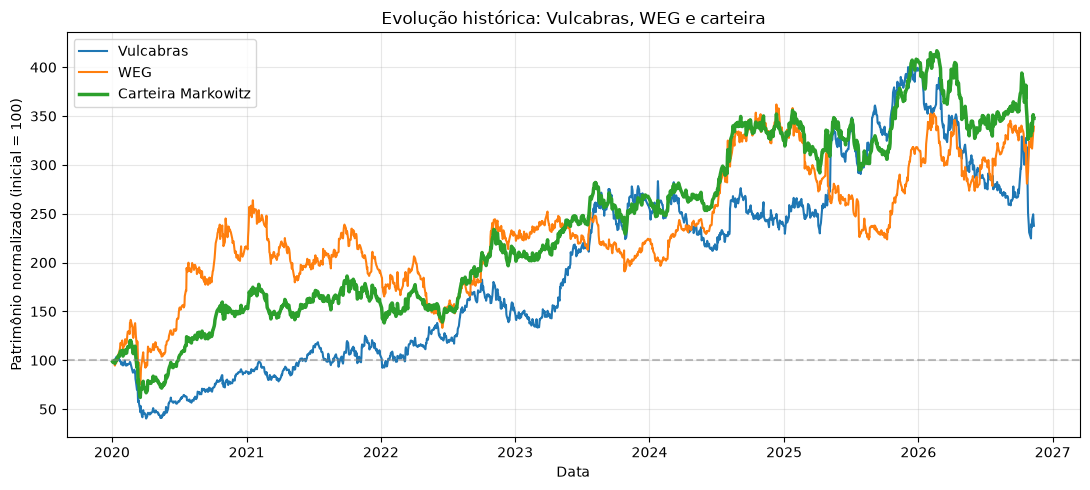

In [93]:

import matplotlib.pyplot as plt
import pandas as pd

# Retornos diários das duas ações
retornos_ativos = retornos_validos[["VULC3.SA", "WEGE3.SA"]]

# Retorno diário da carteira com pesos constantes
retornos_carteira = (
    w1 * retornos_ativos["VULC3.SA"]
    + w2 * retornos_ativos["WEGE3.SA"]
)

# Evolução acumulada começando em 100
evolucao = (1 + retornos_ativos).cumprod() * 100
evolucao["Carteira Markowitz"] = (
    (1 + retornos_carteira).cumprod() * 100
)

# Gráfico
plt.figure(figsize=(11, 5))

plt.plot(evolucao.index, evolucao["VULC3.SA"],
         label="Vulcabras")

plt.plot(evolucao.index, evolucao["WEGE3.SA"],
         label="WEG")

plt.plot(evolucao.index, evolucao["Carteira Markowitz"],
         label="Carteira Markowitz", linewidth=2.5)

plt.axhline(100, linestyle="--", color="gray", alpha=0.5)

plt.title("Evolução histórica: Vulcabras, WEG e carteira")
plt.xlabel("Data")
plt.ylabel("Patrimônio normalizado (inicial = 100)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


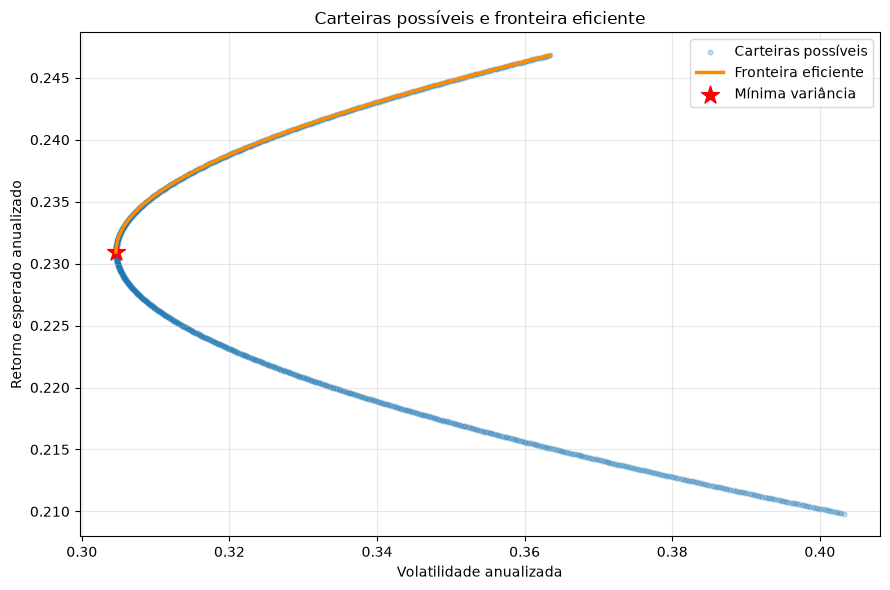

Peso de VULC3.SA na carteira de mínima variância: 42.90%
Peso de WEGE3.SA na carteira de mínima variância: 57.10%


In [94]:
# Fronteira eficiente para os dois ativos do teste
# Pressupõe que as células anteriores já criaram `retornos_validos` e `ativos`.
import numpy as np
import matplotlib.pyplot as plt

retornos_dois_ativos = retornos_validos[ativos].dropna()
mu_diario = retornos_dois_ativos.mean().to_numpy()
cov_diaria = retornos_dois_ativos.cov().to_numpy()

# Variamos o peso do primeiro ativo; o peso do segundo é o que falta para 100%.
peso_1 = np.linspace(0, 1, 1001)
pesos = np.column_stack([peso_1, 1 - peso_1])

retornos_diarios_carteiras = pesos @ mu_diario
variancias_diarias = np.einsum('ij,jk,ik->i', pesos, cov_diaria, pesos)
volatilidades_diarias = np.sqrt(np.maximum(variancias_diarias, 0))

# Anualização aproximada para dados diários (252 pregões por ano).
retornos_anuais = retornos_diarios_carteiras * 252
volatilidades_anuais = volatilidades_diarias * np.sqrt(252)

# Destaca os pontos não dominados: não existe outra carteira com risco menor
# ou igual e retorno maior ou igual.
ordem = np.lexsort((-retornos_anuais, volatilidades_anuais))
indices_eficientes = []
maior_retorno_ate_agora = -np.inf
for i in ordem:
    if retornos_anuais[i] > maior_retorno_ate_agora + 1e-12:
        indices_eficientes.append(i)
        maior_retorno_ate_agora = retornos_anuais[i]

indices_eficientes = np.array(indices_eficientes)
ordem_fronteira = indices_eficientes[np.argsort(volatilidades_anuais[indices_eficientes])]

# Carteira de menor volatilidade entre as combinações testadas.
indice_min_variancia = np.argmin(volatilidades_anuais)

plt.figure(figsize=(9, 6))
plt.scatter(volatilidades_anuais, retornos_anuais,
            s=12, alpha=0.25, label='Carteiras possíveis')
plt.plot(volatilidades_anuais[ordem_fronteira],
         retornos_anuais[ordem_fronteira],
         color='darkorange', linewidth=2.5, label='Fronteira eficiente')
plt.scatter(volatilidades_anuais[indice_min_variancia],
            retornos_anuais[indice_min_variancia],
            color='red', marker='*', s=180, label='Mínima variância')
plt.xlabel('Volatilidade anualizada')
plt.ylabel('Retorno esperado anualizado')
plt.title('Carteiras possíveis e fronteira eficiente')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Peso de {ativos[0]} na carteira de mínima variância: {pesos[indice_min_variancia, 0]:.2%}")
print(f"Peso de {ativos[1]} na carteira de mínima variância: {pesos[indice_min_variancia, 1]:.2%}")


## 5 ativos

- EMBJ3
- ITUB3
- PETR4
- WEGE3
- VULC3


In [ ]:
# Baixa os dados históricos dos cinco ativos e separa calibração e teste.
import numpy as np
import requests
from scipy.optimize import minimize

ativos = ["EMBJ3.SA", "ITUB3.SA", "PETR4.SA", "WEGE3.SA", "VULC3.SA"]
data_inicio_calibracao = "2000-01-01"
data_inicio_teste = "2021-01-01"
ultimo_dia_teste = min(pd.Timestamp.today().normalize(), pd.Timestamp("2026-12-31"))
data_fim = (ultimo_dia_teste + pd.Timedelta(days=1)).strftime("%Y-%m-%d")

# Usa o código atual da Embraer na série histórica.
dados_historicos = yf.download(
    ativos,
    start=data_inicio_calibracao,
    end=data_fim,
    interval="1d",
    auto_adjust=False,
    progress=False,
    group_by="column",
)
precos_carteira = dados_historicos["Adj Close"].reindex(columns=ativos)

# CDI diário do Banco Central (série SGS 12), convertido de % para decimal.
# A API do SGS limita cada consulta de série diária a até 10 anos;
# buscamos em blocos menores e concatenamos a série completa.
limites_cdi = [
    ("01/01/2000", "31/12/2009"),
    ("01/01/2010", "31/12/2019"),
    ("01/01/2020", ultimo_dia_teste.strftime("%d/%m/%Y")),
]
tabelas_cdi = []
for data_inicial_cdi, data_final_cdi in limites_cdi:
    resposta_cdi = requests.get(
        "https://api.bcb.gov.br/dados/serie/bcdata.sgs.12/dados",
        params={
            "formato": "json",
            "dataInicial": data_inicial_cdi,
            "dataFinal": data_final_cdi,
        },
        timeout=30,
    )
    resposta_cdi.raise_for_status()
    tabelas_cdi.extend(resposta_cdi.json())
tabela_cdi = pd.DataFrame(tabelas_cdi)
tabela_cdi["data"] = pd.to_datetime(tabela_cdi["data"], dayfirst=True)
tabela_cdi["valor"] = pd.to_numeric(tabela_cdi["valor"], errors="coerce")
serie_cdi = (tabela_cdi.set_index("data")["valor"] / 100).sort_index().rename("CDI")

print("Primeira data disponível por ativo:")
display(precos_carteira.apply(lambda coluna: coluna.first_valid_index()).rename("Início disponível").to_frame())
precos_comuns = precos_carteira.dropna(how="any")
retornos_diarios_todos = precos_comuns.pct_change(fill_method=None).dropna(how="any")
retornos_calibracao = retornos_diarios_todos.loc[data_inicio_calibracao:"2020-12-31"].dropna(how="any")
retornos_teste = retornos_diarios_todos.loc[data_inicio_teste:].dropna(how="any")

if retornos_calibracao.empty:
    raise ValueError("Não há retornos comuns dos cinco ativos na janela de calibração.")
if retornos_teste.empty:
    raise ValueError("Não há retornos comuns dos cinco ativos na janela de teste.")

print("Janela de calibração disponível:", retornos_calibracao.index.min().date(), "a", retornos_calibracao.index.max().date())
print("Janela de backtest:", retornos_teste.index.min().date(), "a", retornos_teste.index.max().date())
print("Pregões na calibração:", len(retornos_calibracao), "| no teste:", len(retornos_teste))
print("Liquidez financeira média por ativo nos últimos 252 pregões (R$):")
precos_fechamento = dados_historicos["Close"].reindex(columns=ativos)
volumes_carteira = dados_historicos["Volume"].reindex(columns=ativos)
volume_financeiro_carteira = precos_fechamento * volumes_carteira
display(volume_financeiro_carteira.tail(252).mean().sort_values(ascending=False))


In [ ]:
# Estima retorno esperado e matriz de covariância somente na janela de calibração.
retorno_medio_diario = retornos_calibracao.mean()
volatilidade_diaria = retornos_calibracao.std()
matriz_covariancia_diaria = retornos_calibracao.cov()
matriz_correlacao = retornos_calibracao.corr()

print("Retornos médios diários (calibração):")
display(retorno_medio_diario.to_frame("Retorno médio diário"))
print("Volatilidades diárias (calibração):")
display(volatilidade_diaria.to_frame("Volatilidade diária"))
print("Matriz de correlação (calibração):")
display(matriz_correlacao)
print("Matriz de covariância diária (calibração):")
display(matriz_covariancia_diaria)


In [ ]:
# Otimização de Markowitz feita exclusivamente com os dados de 2000 a 2020.
retornos_anuais_ativos = retorno_medio_diario * 252
covariancia_anual = matriz_covariancia_diaria * 252
n_ativos = len(ativos)
pesos_iguais = np.repeat(1 / n_ativos, n_ativos)
limites_pesos = [(0.0, 1.0)] * n_ativos
restricao_soma = {"type": "eq", "fun": lambda pesos: np.sum(pesos) - 1}

cdi_calibracao = serie_cdi.reindex(retornos_calibracao.index).dropna()
if cdi_calibracao.empty:
    raise ValueError("Não há observações de CDI alinhadas à janela de calibração.")
taxa_livre_risco_anual = (1 + cdi_calibracao).prod() ** (252 / len(cdi_calibracao)) - 1


def volatilidade_anualizada(pesos):
    return float(np.sqrt(pesos @ covariancia_anual.to_numpy() @ pesos))


resultado_min_variancia = minimize(
    lambda pesos: pesos @ covariancia_anual.to_numpy() @ pesos,
    pesos_iguais,
    method="SLSQP",
    bounds=limites_pesos,
    constraints=[restricao_soma],
    options={"maxiter": 2000, "ftol": 1e-12},
)
if not resultado_min_variancia.success:
    raise RuntimeError(f"Otimização de mínima variância falhou: {resultado_min_variancia.message}")
pesos_min_variancia = resultado_min_variancia.x


def menos_sharpe(pesos):
    retorno = float(pesos @ retornos_anuais_ativos.to_numpy())
    risco = volatilidade_anualizada(pesos)
    return -(retorno - taxa_livre_risco_anual) / risco


resultado_max_sharpe = minimize(
    menos_sharpe,
    pesos_iguais,
    method="SLSQP",
    bounds=limites_pesos,
    constraints=[restricao_soma],
    options={"maxiter": 2000, "ftol": 1e-12},
)
if not resultado_max_sharpe.success:
    raise RuntimeError(f"Otimização de Sharpe falhou: {resultado_max_sharpe.message}")
pesos_max_sharpe = resultado_max_sharpe.x


def resumo_carteira(nome, pesos):
    retorno = float(pesos @ retornos_anuais_ativos.to_numpy())
    risco = volatilidade_anualizada(pesos)
    sharpe = (retorno - taxa_livre_risco_anual) / risco
    print(f"\n{nome}")
    display(pd.Series(pesos, index=ativos, name="Peso").to_frame().style.format("{:.2%}"))
    print(f"Retorno esperado anualizado: {retorno:.2%}")
    print(f"Volatilidade anualizada: {risco:.2%}")
    print(f"Índice de Sharpe (CDI médio anualizado da calibração): {sharpe:.3f}")


print(f"Taxa livre de risco anualizada na calibração (CDI): {taxa_livre_risco_anual:.2%}")
resumo_carteira("Carteira de mínima variância", pesos_min_variancia)
resumo_carteira("Carteira de máximo Sharpe / tangência", pesos_max_sharpe)


In [ ]:
# Fronteira eficiente estimada na calibração; resultados aplicados fora da amostra em 2021–2026.
import matplotlib.pyplot as plt

retornos_alvo = np.linspace(retornos_anuais_ativos.min(), retornos_anuais_ativos.max(), 60)
pontos_fronteira = []
for retorno_alvo in retornos_alvo:
    restricoes = [
        restricao_soma,
        {"type": "eq", "fun": lambda pesos, alvo=retorno_alvo: pesos @ retornos_anuais_ativos.to_numpy() - alvo},
    ]
    resultado = minimize(
        lambda pesos: pesos @ covariancia_anual.to_numpy() @ pesos,
        pesos_iguais,
        method="SLSQP",
        bounds=limites_pesos,
        constraints=restricoes,
        options={"maxiter": 2000, "ftol": 1e-12},
    )
    if resultado.success:
        pontos_fronteira.append((volatilidade_anualizada(resultado.x), retorno_alvo))

fronteira = np.asarray(pontos_fronteira)
risco_minimo = volatilidade_anualizada(pesos_min_variancia)
retorno_minimo = float(pesos_min_variancia @ retornos_anuais_ativos.to_numpy())
if len(fronteira):
    fronteira = fronteira[fronteira[:, 1] >= retorno_minimo - 1e-10]
risco_sharpe = volatilidade_anualizada(pesos_max_sharpe)
retorno_sharpe = float(pesos_max_sharpe @ retornos_anuais_ativos.to_numpy())

plt.figure(figsize=(10, 6))
plt.scatter(
    np.sqrt(np.diag(covariancia_anual.to_numpy())),
    retornos_anuais_ativos,
    label="Ativos individuais (calibração)",
    s=55,
)
for ativo, risco, retorno in zip(ativos, np.sqrt(np.diag(covariancia_anual.to_numpy())), retornos_anuais_ativos):
    plt.annotate(ativo.replace(".SA", ""), (risco, retorno), xytext=(5, 5), textcoords="offset points")
if len(fronteira):
    ordem = np.argsort(fronteira[:, 0])
    plt.plot(fronteira[ordem, 0], fronteira[ordem, 1], color="darkorange", linewidth=2.5, label="Fronteira eficiente")
plt.scatter(risco_minimo, retorno_minimo, color="red", marker="*", s=180, label="Mínima variância")
plt.scatter(risco_sharpe, retorno_sharpe, color="green", marker="*", s=180, label="Máximo Sharpe / tangência")
plt.xlabel("Volatilidade anualizada")
plt.ylabel("Retorno esperado anualizado")
plt.title("Fronteira eficiente: calibração 2000–2020")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Pesos definidos na calibração ficam congelados durante todo o teste.
retornos_carteiras_teste = pd.DataFrame(
    {
        "Carteira mínima variância": retornos_teste @ pesos_min_variancia,
        "Carteira máximo Sharpe": retornos_teste @ pesos_max_sharpe,
    },
    index=retornos_teste.index,
)
evolucao_teste_ativos = (1 + retornos_teste).cumprod() * 100
evolucao_teste_carteiras = (1 + retornos_carteiras_teste).cumprod() * 100

plt.figure(figsize=(12, 6))
for ativo in ativos:
    plt.plot(evolucao_teste_ativos.index, evolucao_teste_ativos[ativo], alpha=0.55, label=ativo.replace(".SA", ""))
for carteira in evolucao_teste_carteiras.columns:
    plt.plot(evolucao_teste_carteiras.index, evolucao_teste_carteiras[carteira], linewidth=2.5, label=carteira)
plt.axhline(100, linestyle="--", color="gray", alpha=0.5)
plt.title("Backtest fora da amostra: 2021–2026")
plt.xlabel("Data")
plt.ylabel("Patrimônio normalizado (inicial = 100)")
plt.grid(alpha=0.3)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()


## Comparação com CDI e Ibovespa


In [ ]:
# Compara o backtest de 2021–2026 com Ibovespa e CDI nas mesmas datas.
ibov_download = yf.download(
    "^BVSP",
    start="2020-12-30",  # inclui o fechamento anterior para calcular o primeiro retorno de 2021
    end=data_fim,
    interval="1d",
    auto_adjust=False,
    progress=False,
)
ibov_precos = ibov_download["Adj Close"]
if isinstance(ibov_precos, pd.DataFrame):
    ibov_precos = ibov_precos.iloc[:, 0]
retorno_ibovespa = ibov_precos.pct_change(fill_method=None).loc[data_inicio_teste:].rename("Ibovespa")

retorno_cdi_teste = serie_cdi.loc[data_inicio_teste:].rename("CDI")
retornos_comparacao = pd.concat(
    [retornos_carteiras_teste, retorno_ibovespa, retorno_cdi_teste], axis=1
).dropna()
if retornos_comparacao.empty:
    raise ValueError("Não há datas em comum entre as carteiras, o CDI e o Ibovespa.")

patrimonio_comparacao = (1 + retornos_comparacao).cumprod() * 100
print(
    "Período comum do backtest:",
    retornos_comparacao.index.min().date(),
    "a",
    retornos_comparacao.index.max().date(),
    "| pregões:",
    len(retornos_comparacao),
)

resumo_comparacao = pd.DataFrame(index=retornos_comparacao.columns)
resumo_comparacao["Retorno acumulado"] = patrimonio_comparacao.iloc[-1] / 100 - 1
resumo_comparacao["CAGR"] = (patrimonio_comparacao.iloc[-1] / 100) ** (252 / len(retornos_comparacao)) - 1
resumo_comparacao["Volatilidade anualizada"] = retornos_comparacao.std() * np.sqrt(252)
coluna_sharpe = "Sharpe (Rf = CDI)"
resumo_comparacao[coluna_sharpe] = np.nan
for serie in ["Carteira mínima variância", "Carteira máximo Sharpe", "Ibovespa"]:
    excesso = retornos_comparacao[serie] - retornos_comparacao["CDI"]
    desvio_excesso = excesso.std()
    resumo_comparacao.loc[serie, coluna_sharpe] = (
        excesso.mean() / desvio_excesso * np.sqrt(252) if desvio_excesso > 0 else np.nan
    )
display(resumo_comparacao.style.format({
    "Retorno acumulado": "{:.2%}",
    "CAGR": "{:.2%}",
    "Volatilidade anualizada": "{:.2%}",
    coluna_sharpe: "{:.3f}",
}))

plt.figure(figsize=(12, 6))
for serie in patrimonio_comparacao.columns:
    plt.plot(patrimonio_comparacao.index, patrimonio_comparacao[serie], linewidth=2, label=serie)
plt.axhline(100, linestyle="--", color="gray", alpha=0.5)
plt.title("Backtest 2021–2026: carteiras Markowitz, CDI e Ibovespa")
plt.xlabel("Data")
plt.ylabel("Patrimônio acumulado (inicial = 100)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
